# Research Navigator -- Beyond Horizons

This notebook runs this project's own `app.domain.research_navigator` module and shows its real output: the three hypothetical experiment proposals, ranked by the project's priority formula
(`priority = mission_impact * uncertainty * expected_information_gain / relative_cost`).

**No numbers in this notebook's outputs are typed in by hand.** Every value below was produced by actually importing and calling the project's code; see `docs/methodology.md` and `app/schemas/research.py` for how `priority` is computed as a schema-level `computed_field`, not a settable number.


In [1]:
from app.domain.research_navigator import build_research_proposals

for p in build_research_proposals():
    print(f"{p.id:35s} impact={p.mission_impact:.2f} "
          f"uncertainty={p.uncertainty:.2f} info_gain={p.expected_information_gain:.2f} "
          f"cost={p.relative_cost:.2f}")


radiation-sleep-cognition           impact=0.80 uncertainty=0.55 info_gain=0.60 cost=1.50
microgravity-muscle-bone            impact=0.75 uncertainty=0.60 info_gain=0.65 cost=2.00
isolation-circadian-performance     impact=0.60 uncertainty=0.70 info_gain=0.50 cost=1.20


In [2]:
from app.domain.research_navigator import rank_research_proposals

ranked = rank_research_proposals()
for rank, p in enumerate(ranked, start=1):
    print(f"{rank}. {p.title:40s} priority={p.priority:.4f}")


1. Radiation + Sleep + Cognition            priority=0.1760
2. Isolation + Circadian Rhythm + Performance priority=0.1750
3. Microgravity + Muscle + Bone             priority=0.1462


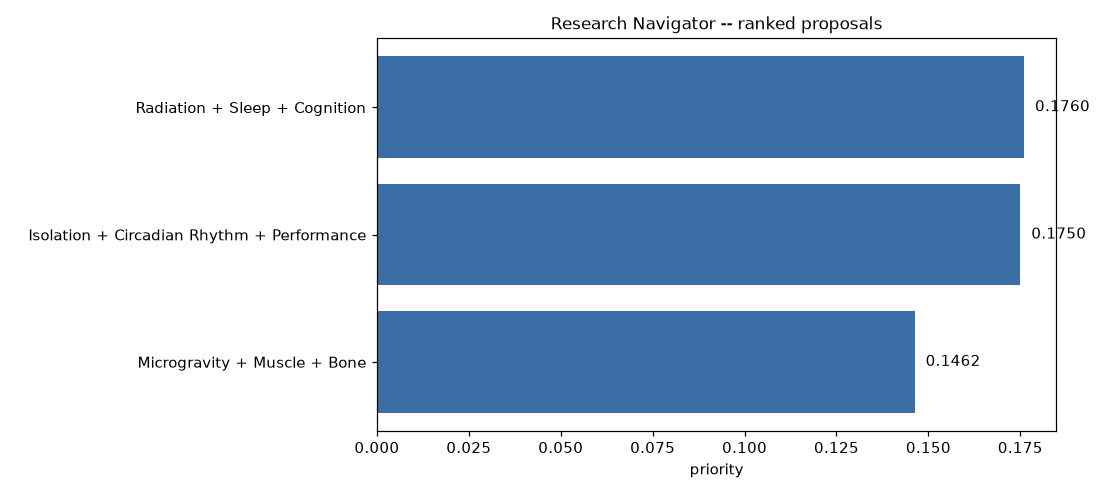

In [3]:
import matplotlib.pyplot as plt

ranked = rank_research_proposals()
titles = [p.title for p in ranked]
priorities = [p.priority for p in ranked]

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(titles, priorities, color="#3B6EA5")
ax.set_xlabel("priority")
ax.set_title("Research Navigator -- ranked proposals", fontsize=11)
ax.invert_yaxis()
for bar, value in zip(bars, priorities):
    ax.text(value + 0.003, bar.get_y() + bar.get_height() / 2, f"{value:.4f}", va="center")
fig.tight_layout()
plt.show()


## Reading this chart

The ranking is close between the top two proposals (0.1760 vs 0.1750) -- both target gaps that are, in this project's own judgment, nearly equally worth investigating next. The third proposal (bone+muscle) ranks lower mainly because of its higher `relative_cost` (a longitudinal combined study costs more than a shorter ground analog), not because its gap matters less.

None of these are real NASA studies -- see each proposal's `limitations` field, and `docs/methodology.md` for the full Research Navigator section.
